In [43]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os 
import csv
import time
import re
import pickle as pkl
import seaborn as sns
import matplotlib.colors as mcolors
import importlib
import Microstates_Maximum_Entropy as mme

importlib.reload(mme)


<module 'Microstates_Maximum_Entropy' from '/home/diogoma/Dropbox/Diogo/Intermittency_microstates/GitHub repository/Microstates_Maximum_Entropy.py'>

In [45]:
data = pd.read_csv('PSP_g4.0_gsyn1.424.dat', names=['time', 'psp'], sep = '\t')



########## Microstate Maximum entropy parameters #########
StatsBlock=3# tamanho das submatrizes do RM (N x N = statsblock x statsblock)
samples = 20000
##################################

aux_Smax = []
aux_eps= []
aux_stats= [] # this storages how many times each microstate appears
aux_time = []

window = 1000 # ms
step = 500 #ms
############### Computing maximum entropy for each time bin ######
for interval in range(0, len(data['psp'])- window, step):

    Serie = data['psp'][interval: interval + window]  
    results = mme.compute_MaxEntropy(Serie, StatsBlock = StatsBlock, samples = samples)

    aux_Smax.append(results['Smax'])
    aux_time.append(interval/1000) # s

#########################################

df = pd.DataFrame({
    'time': aux_time,
    'Smax': aux_Smax
})

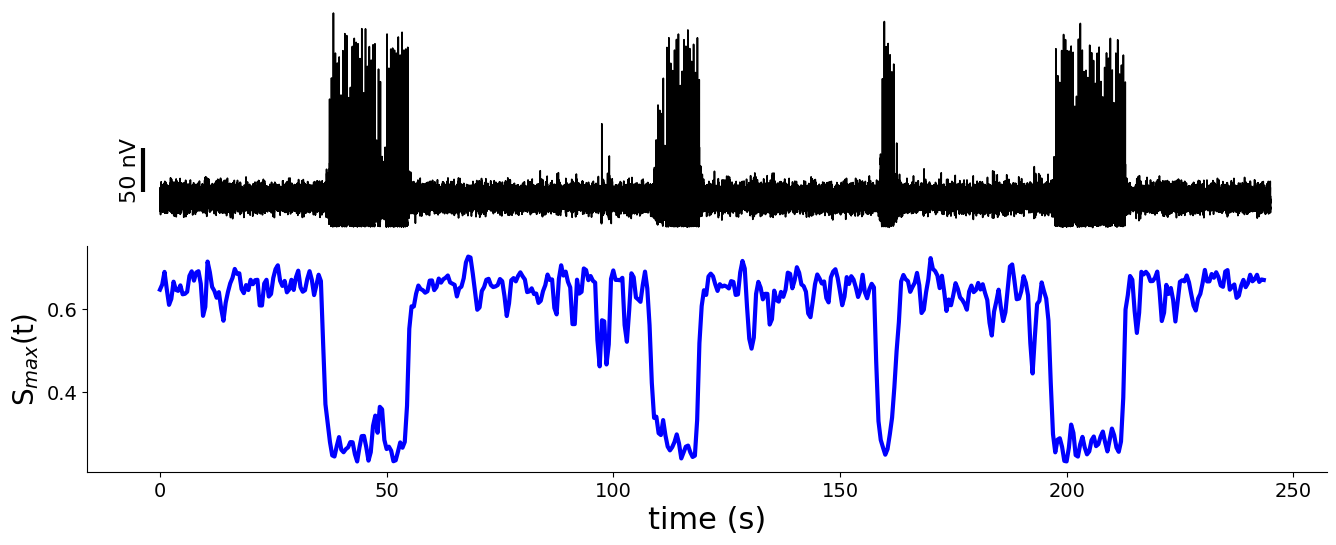

In [46]:
t_smax = df['time'].values
smax = df['Smax'].values

# -------------------------
# plot
# -------------------------
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(16, 6), sharex=True,
    gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.05}
)

# ---- first panel: PSP
axes[0].plot(data['time'], data['psp'], color='black', lw=1.2)
axes[0].set_ylim(-10, 250)


# remove x-axis from first panel
axes[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
axes[0].spines['bottom'].set_visible(False)

# remove y-axis from first panel
axes[0].set_ylabel('')
axes[0].set_yticks([])
axes[0].spines['left'].set_visible(False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# vertical scale bar = 50 nV
x_min, x_max = data['time'].min(), data['time'].max()
xrange_ = x_max - x_min

x_bar = x_min - 0.015 * xrange_
y_bar0 = 40
bar_size = 50

axes[0].plot([x_bar, x_bar], [y_bar0, y_bar0 + bar_size],
             color='black', lw=3, solid_capstyle='butt')
axes[0].text(x_bar - 0.012 * xrange_, y_bar0 + bar_size / 2,
             '50 nV', rotation=90, va='center', ha='center', fontsize=16)

# ---- second panel: Smax
axes[1].plot(t_smax, smax, color='blue', lw=3)

axes[1].set_ylabel(r'S$_{max}$(t)', fontsize=20)
axes[1].set_xlabel('time (s)', fontsize=22)
axes[1].tick_params(axis='both', labelsize=14)

axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

sns.despine(ax=axes[1])
plt.show()

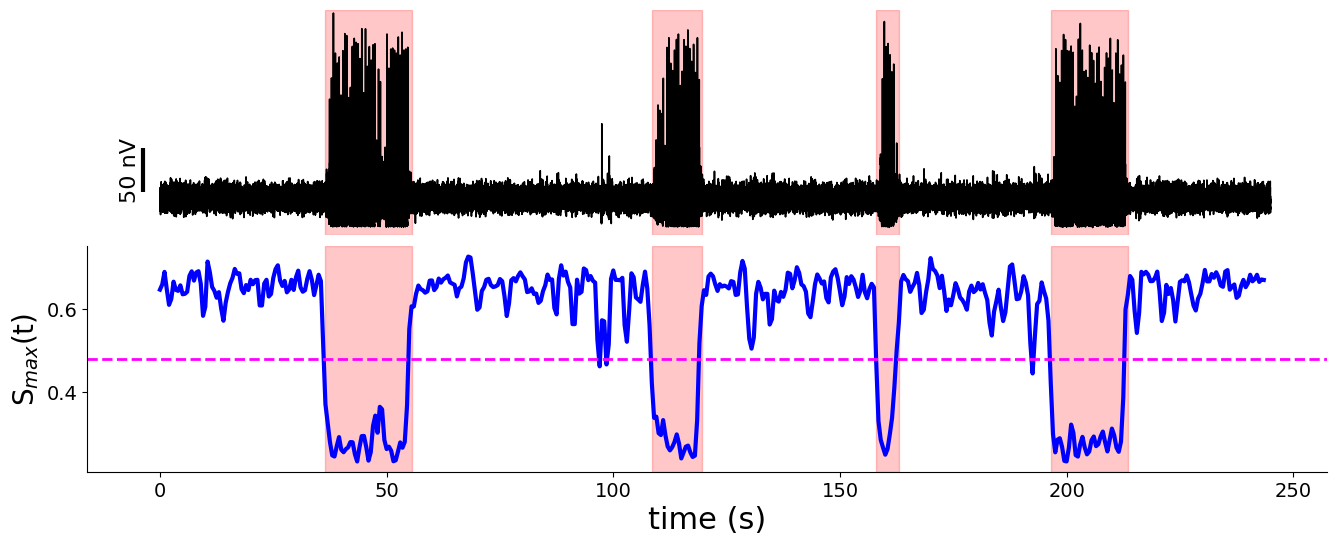

In [48]:
# -------------------------
# threshold
# -------------------------
tinitial = 0.0 #s interval of a down state
tfinal = 10.0 #s

ti = int((1/df['time'][1])*tinitial)
tf = int((1/df['time'][1])*tfinal) + 1

t_smax = df['time'].values
smax = df['Smax'].values
mean = np.mean(smax[ti:tf])
desv = np.std(smax[ti:tf])
thres = mean - 6*desv

step_s = step / 1000

# -------------------------
# detect seizures
# start: Smax < thres
# end:   Smax > mean
# -------------------------
seizure_intervals = []
in_seizure = False
start_idx = None

for i in range(len(smax)):
    if not in_seizure:
        if smax[i] < thres:
            in_seizure = True
            start_idx = i
    else:
        if smax[i] > thres:
            end_idx = i
            t0 = t_smax[start_idx]
            t1 = t_smax[end_idx] + step_s

            if (t1 - t0) >= 2:
                seizure_intervals.append((t0, t1))

            in_seizure = False
            start_idx = None

if in_seizure:
    t0 = t_smax[start_idx]
    t1 = t_smax[-1] + step_s
    if (t1 - t0) >= 2:
        seizure_intervals.append((t0, t1))

# -------------------------
# plot
# -------------------------
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(16, 6), sharex=True,
    gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.05}
)

# ---- first panel: PSP
axes[0].plot(data['time'], data['psp'], color='black', lw=1.2)
axes[0].set_ylim(-10, 250)

for t0, t1 in seizure_intervals:
    axes[0].axvspan(t0, t1, color='red', alpha=0.22, zorder=0)


axes[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
axes[0].spines['bottom'].set_visible(False)
axes[0].set_ylabel('')
axes[0].set_yticks([])
axes[0].spines['left'].set_visible(False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

x_min, x_max = data['time'].min(), data['time'].max()
xrange_ = x_max - x_min

x_bar = x_min - 0.015 * xrange_
y_bar0 = 40
bar_size = 50

axes[0].plot([x_bar, x_bar], [y_bar0, y_bar0 + bar_size],
             color='black', lw=3, solid_capstyle='butt')
axes[0].text(x_bar - 0.012 * xrange_, y_bar0 + bar_size / 2,
             '50 nV', rotation=90, va='center', ha='center', fontsize=16)

# ---- second panel: Smax
axes[1].plot(t_smax, smax, color='blue', lw=3)
axes[1].axhline(thres, linestyle='--', color='magenta', lw=2)

for t0, t1 in seizure_intervals:
    axes[1].axvspan(t0, t1, color='red', alpha=0.22, zorder=0)

axes[1].set_ylabel(r'S$_{max}$(t)', fontsize=20)
axes[1].set_xlabel('time (s)', fontsize=22)
axes[1].tick_params(axis='both', labelsize=14)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

sns.despine(ax=axes[1])
plt.show()